# Análise de Mortes Violentas por Local de Ocorrência
## Sprint 1 - PyAnalytics

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

In [3]:
df = pd.read_csv("../../data/processed/sim_sc_processado_analitico.csv")
df.head()

C:\Users\lucas\AppData\Local\Temp\ipykernel_23620\2361278397.py:1: DtypeWarning: Columns (0: DTOBITO, 1: DTNASC, 2: RACACOR, 3: ESC, 4: IDADEMAE, 5: ESCMAE, 6: GESTACAO, 7: LINHAA, 8: LINHAB, 9: LINHAC, 10: LINHAD, 11: LINHAII) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("../../data/processed/sim_sc_processado_analitico.csv")


,CONTADOR,TIPOBITO,DTOBITO,HORAOBITO,NATURAL,CODMUNNATU,DTNASC,IDADE,SEXO,RACACOR,...,RACACOR_COD,LOCOCOR_COD,IDADE_COD,IDADE_ANOS,ANO_OBITO,ANO_NASC,DATA_OBITO_VALIDA,DATA_NASC_VALIDA,SC_RESIDENCIA,SC_OCORRENCIA
0,2527,2,2000-12-12,NaN,800.0,NaN,1933-11-01,467.0,Masculino,Preta,...,2.0,3.0,467.0,67.0,2000.0,1933.0,True,True,False,True
1,14333,2,2000-11-19,NaN,850.0,NaN,1978-10-20,422.0,Masculino,Branca,...,1.0,5.0,422.0,22.0,2000.0,1978.0,True,True,False,True
2,14334,2,2000-10-16,NaN,842.0,NaN,1910-05-31,490.0,Masculino,Branca,...,1.0,1.0,490.0,90.0,2000.0,1910.0,True,True,False,True
3,51178,2,2000-07-05,NaN,NaN,NaN,1949-12-10,450.0,Masculino,Parda,...,4.0,9.0,450.0,50.0,2000.0,1949.0,True,True,False,True
4,109,2,2000-02-02,NaN,800.0,NaN,1979-05-07,420.0,Masculino,Branca,...,1.0,5.0,420.0,20.0,2000.0,1979.0,True,True,False,True


## 1. Preparação dos Dados

In [4]:
print(df.columns.tolist())
df.info()

['CONTADOR', 'TIPOBITO', 'DTOBITO', 'HORAOBITO', 'NATURAL', 'CODMUNNATU', 'DTNASC', 'IDADE', 'SEXO', 'RACACOR', 'ESTCIV', 'ESC', 'ESC2010', 'SERIESCFAL', 'OCUP', 'CODMUNRES', 'LOCOCOR', 'CODMUNOCOR', 'IDADEMAE', 'ESCMAE', 'ESCMAE2010', 'SERIESCMAE', 'OCUPMAE', 'QTDFILVIVO', 'QTDFILMORT', 'GRAVIDEZ', 'GESTACAO', 'PARTO', 'OBITOPARTO', 'PESO', 'OBITOGRAV', 'OBITOPUERP', 'ASSISTMED', 'EXAME', 'CIRURGIA', 'NECROPSIA', 'CAUSABAS', 'LINHAA', 'LINHAB', 'LINHAC', 'LINHAD', 'LINHAII', 'CIRCOBITO', 'ACIDTRAB', 'FONTE', 'DTOBITO_BRUTO', 'DTNASC_BRUTO', 'SEXO_COD', 'RACACOR_COD', 'LOCOCOR_COD', 'IDADE_COD', 'IDADE_ANOS', 'ANO_OBITO', 'ANO_NASC', 'DATA_OBITO_VALIDA', 'DATA_NASC_VALIDA', 'SC_RESIDENCIA', 'SC_OCORRENCIA']
<class 'pandas.DataFrame'>
RangeIndex: 1502195 entries, 0 to 1502194
Data columns (total 58 columns):
 #   Column             Non-Null Count    Dtype  
---  ------             --------------    -----  
 0   CONTADOR           1502195 non-null  int64  
 1   TIPOBITO           1502195

In [5]:
# Verifica valores nulos nas colunas que vamos usar
colunas_interesse = ["LOCOCOR", "IDADE", "ASSISTMED", "CAUSABAS", "CODMUNOCOR"]
df[colunas_interesse].isnull().sum()

LOCOCOR         2108
IDADE            172
ASSISTMED     262839
CAUSABAS           0
CODMUNOCOR         0
dtype: int64

In [6]:
# Exemplos de linhas nulas em LOCOCOR
print("LOCOCOR nulos")
df[df["LOCOCOR"].isna()][["CONTADOR", "LOCOCOR", "IDADE", "ASSISTMED", "CAUSABAS", "CODMUNOCOR"]].head(10)

LOCOCOR nulos


,CONTADOR,LOCOCOR,IDADE,ASSISTMED,CAUSABAS,CODMUNOCOR
1288094,111,NaN,419.0,2.0,8147,4207304
1289231,996,NaN,454.0,2.0,9289,4216602
1289313,1078,NaN,480.0,2.0,7989,4205407
1289318,1083,NaN,460.0,2.0,7989,4200606
1289341,1106,NaN,456.0,1.0,2503,4205407
1289342,1107,NaN,454.0,1.0,8199,4200903
1289400,1165,NaN,428.0,1.0,8199,4205407
1289492,1257,NaN,464.0,1.0,486X,4202909
1289494,1259,NaN,491.0,NaN,797X,4202909
1289798,1563,NaN,462.0,NaN,436X,4216305


In [7]:
# Exemplos de linhas nulas em IDADE
print("IDADE nulos")
df[df["IDADE"].isna()][["CONTADOR", "LOCOCOR", "IDADE", "ASSISTMED", "CAUSABAS", "CODMUNOCOR"]].head(10)

IDADE nulos


,CONTADOR,LOCOCOR,IDADE,ASSISTMED,CAUSABAS,CODMUNOCOR
182746,4166,Hospital,NaN,NaN,P021,420320
188961,10381,Hospital,NaN,NaN,P022,420330
189789,11209,Outros,NaN,NaN,Y098,421580
200900,22320,Hospital,NaN,1.0,P025,421175
1390424,191,Hospital,NaN,1.0,C719,4106902
1390604,371,Outros,NaN,2.0,V892,4106902
1390618,385,NaN,NaN,1.0,K746,4106902
1391487,1254,Via publica,NaN,1.0,V892,4205704
1392249,2016,NaN,NaN,9.0,I219,4207908
1393447,3214,NaN,NaN,1.0,J988,4209003


In [8]:
# Exemplos de linhas nulas em ASSISTMED
print("ASSISTMED nulos")
df[df["ASSISTMED"].isna()][["CONTADOR", "LOCOCOR", "IDADE", "ASSISTMED", "CAUSABAS", "CODMUNOCOR"]].head(10)

ASSISTMED nulos


,CONTADOR,LOCOCOR,IDADE,ASSISTMED,CAUSABAS,CODMUNOCOR
0,2527,Domicilio,467.0,NaN,J449,4216909
1,14333,Outros,422.0,NaN,W698,4211405
2,14334,Hospital,490.0,NaN,J439,4203303
3,51178,Ignorado,450.0,NaN,C786,4207684
4,109,Outros,420.0,NaN,W698,4211900
5,147,Via publica,440.0,NaN,I255,4201950
6,95695,Outros,418.0,NaN,W698,4202107
7,249,Hospital,102.0,NaN,P392,4209102
10,6259,Domicilio,457.0,NaN,C64,4219101
11,51872,Outros,438.0,NaN,X938,4208203


In [9]:
# Verifica duplicatas
duplicatas = df.duplicated()
print(f"Total de linhas duplicadas: {duplicatas.sum()}")
df[duplicatas].head(10)

Total de linhas duplicadas: 0


,CONTADOR,TIPOBITO,DTOBITO,HORAOBITO,NATURAL,CODMUNNATU,DTNASC,IDADE,SEXO,RACACOR,...,RACACOR_COD,LOCOCOR_COD,IDADE_COD,IDADE_ANOS,ANO_OBITO,ANO_NASC,DATA_OBITO_VALIDA,DATA_NASC_VALIDA,SC_RESIDENCIA,SC_OCORRENCIA


### Observações sobre Valores Ausentes

- **LOCOCOR**: 13 registros sem local de óbito em Araranguá — removidos via `dropna`, pois o local é a variável central da análise. Perda de menos de 0,2%, desprezível.
- **IDADE**: poucos registros ausentes — mantidos. Os gráficos usam `IDADE_ANOS` (derivada pelo pipeline); registros sem idade simplesmente não aparecem no boxplot.
- **ASSISTMED**: expressivo número de ausências no dataset geral de SC. Mantidos e classificados como "Não informado" nos gráficos, sem imputação, para não distorcer a análise.
- **Duplicatas**: nenhuma encontrada.

## Filtro para Araranguá — Mortes Violentas (CID V–Y)

In [10]:
CODIGO_ARARANGUA = 4201406

# Filtra apenas mortes violentas (causas externas CID V-Y)
mascara_violenta = df["CAUSABAS"].astype(str).str.match(r"^[V-Y]", na=False)

df_limpo = (
    df[(df["CODMUNOCOR"] == CODIGO_ARARANGUA) & mascara_violenta]
    .dropna(subset=["LOCOCOR"])
    .copy()
)

# Mapeia ASSISTMED para texto legível
mapa_assistmed = {1.0: "Sim", 2.0: "Não", 9.0: "Ignorado"}
df_limpo["ASSISTMED_LABEL"] = df_limpo["ASSISTMED"].map(mapa_assistmed).fillna("Não informado")

print(f"Total de mortes violentas em Araranguá: {len(df_limpo)}")

Total de mortes violentas em Araranguá: 450


In [11]:
print(f"Antes do dropna: {len(df[(df['CODMUNOCOR'] == CODIGO_ARARANGUA) & mascara_violenta])}")
print(f"Depois do dropna: {len(df_limpo)}")
print(f"Removidos: {len(df[(df['CODMUNOCOR'] == CODIGO_ARARANGUA) & mascara_violenta]) - len(df_limpo)}")

Antes do dropna: 453
Depois do dropna: 450
Removidos: 3


## Normalização por Habitantes

In [12]:
# População de Araranguá — Censo IBGE 2022
POP_ARARANGUA = 107089

taxa_geral = len(df_limpo) / POP_ARARANGUA * 100000
print(f"Taxa de mortalidade violenta em Araranguá: {taxa_geral:.1f} mortes por 100.000 habitantes")

# Taxa por local de ocorrência
contagem_local_raw = df_limpo["LOCOCOR"].value_counts()
taxa_por_local = (contagem_local_raw / POP_ARARANGUA * 100000).round(2)
print("\nTaxa por local (por 100.000 hab):")
print(taxa_por_local)

Taxa de mortalidade violenta em Araranguá: 420.2 mortes por 100.000 habitantes

Taxa por local (por 100.000 hab):
LOCOCOR
Hospital       168.08
Via publica    163.42
Domicilio       41.09
Outros          36.42
Ignorado        11.21
Name: count, dtype: float64


**Interpretação:** A taxa de mortalidade violenta expressa quantas mortes violentas ocorrem para cada 100.000 habitantes. Esse indicador permite comparar Araranguá com outros municípios de forma justa, independentemente do tamanho populacional de cada um.

## 2. Análise Comparativa de Proporção (Local x Idade)

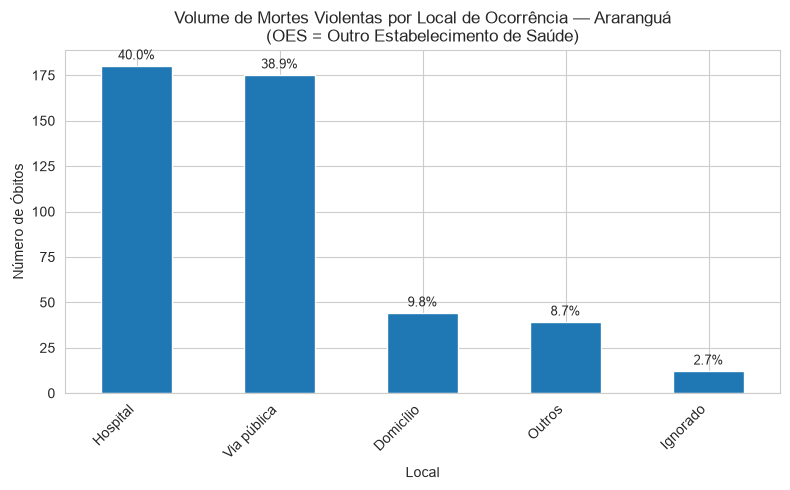

In [13]:
mapa_local = {
    "Hospital": "Hospital",
    "Domicilio": "Domicílio",
    "Via publica": "Via pública",
    "Outro estabelecimento de saude": "OES",
    "Outros": "Outros",
    "Aldeia indigena": "Ald. Indígena",
    "Ignorado": "Ignorado"
}

contagem_local = df_limpo["LOCOCOR"].value_counts()
contagem_local.index = contagem_local.index.map(lambda x: mapa_local.get(x, x))
total = contagem_local.sum()

fig, ax = plt.subplots(figsize=(8,5))
bars = contagem_local.plot(kind="bar", ax=ax)
plt.title("Volume de Mortes Violentas por Local de Ocorrência — Araranguá\n(OES = Outro Estabelecimento de Saúde)")
plt.xlabel("Local")
plt.ylabel("Número de Óbitos")
plt.xticks(rotation=45, ha="right")

# Adiciona percentual em cada barra
for bar in ax.patches:
    pct = bar.get_height() / total * 100
    ax.annotate(f"{pct:.1f}%",
                xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
                xytext=(0, 3), textcoords="offset points",
                ha="center", va="bottom", fontsize=9)

plt.tight_layout()
plt.show()

**Interpretação:** O gráfico mostra a distribuição das mortes violentas por local de ocorrência. A via pública tende a concentrar óbitos por acidentes de trânsito e agressões, enquanto o hospital recebe vítimas que chegaram com vida mas não sobreviveram. A proporção de óbitos em domicílio pode indicar eventos sem atendimento de emergência.

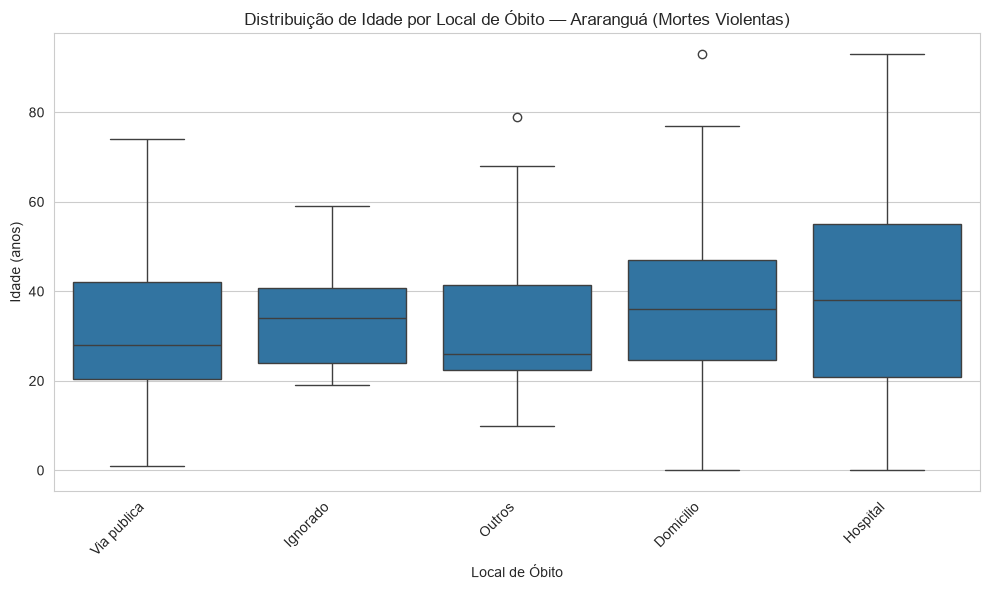

In [14]:
plt.figure(figsize=(10,6))
sns.boxplot(data=df_limpo, x="LOCOCOR", y="IDADE_ANOS")
plt.title("Distribuição de Idade por Local de Óbito — Araranguá (Mortes Violentas)")
plt.xlabel("Local de Óbito")
plt.ylabel("Idade (anos)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

> **Nota:** Os pontos fora das caixas são outliers — casos com idade atípica em relação ao padrão daquele local. A caixa representa 50% dos casos centrais e a linha do meio é a mediana.

**Interpretação:** Diferenças na faixa etária entre locais revelam perfis distintos de vítimas. Mortes em via pública tendem a atingir adultos jovens (acidentes, violência); mortes em domicílio podem ter mediana de idade mais alta, associadas a eventos em idosos.

## 3. Indicador de Amparo Médico

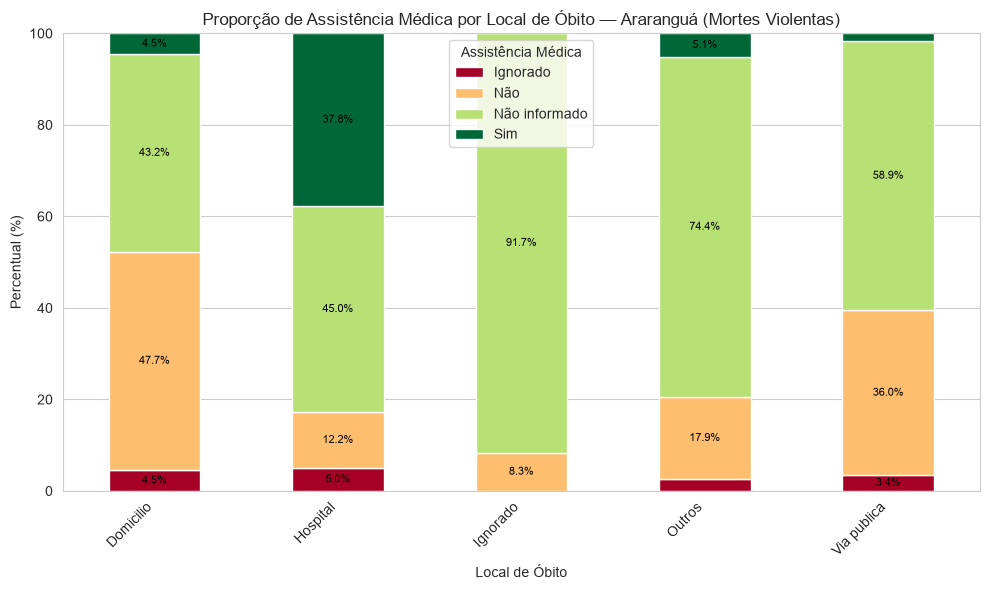

In [15]:
tabela_assist = pd.crosstab(
    df_limpo["LOCOCOR"],
    df_limpo["ASSISTMED_LABEL"],
    normalize="index"
) * 100

ax = tabela_assist.plot(kind="bar", stacked=True, figsize=(10,6), colormap="RdYlGn")
plt.title("Proporção de Assistência Médica por Local de Óbito — Araranguá (Mortes Violentas)")
plt.ylabel("Percentual (%)")
plt.xlabel("Local de Óbito")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Assistência Médica")

# Adiciona percentual em cada segmento
for bar in ax.patches:
    height = bar.get_height()
    if height > 3:
        ax.annotate(f"{height:.1f}%",
                    xy=(bar.get_x() + bar.get_width() / 2, bar.get_y() + height / 2),
                    ha="center", va="center", fontsize=8, color="black")

plt.tight_layout()
plt.show()

**Interpretação:** O gráfico evidencia em quais locais as vítimas tiveram (ou não) assistência médica antes da morte. Alta proporção de "Não" em via pública ou domicílio caracteriza mortes desamparadas — sem atendimento prévio — o que pode indicar necessidade de melhora na cobertura de emergências nesses ambientes.

## 4. Georreferenciamento das Ocorrências

In [ ]:
mapa_municipios_abrev = {
  4201406: "Araranguá",
    4203006: "Caçador",
    4203808: "Canoinhas",
    4204806: "Curitibanos",
    4205407: "Florianópolis",
    4207007: "Içara",
    4207304: "Imbituba",
    4207502: "Indaial",
    4208203: "Itajaí",
    4209003: "Joaçaba",
    4209102: "Joinville",
    4209409: "Laguna",
    4210100: "Mafra",
    4211405: "Palhoça",
    4211900: "Palhoça",
    4213104: "Rio do Sul",
    4213609: "Porto União",
    4215802: "São Bento do Sul",
    4217204: "São Miguel do Oeste",
    4218202: "Timbó",
    4219101: "Tubarão",
    4219309: "Videira",
    4219507: "Xanxerê",
}

Araranguá está na posição 46 de SC
Com 6909 óbitos registrados


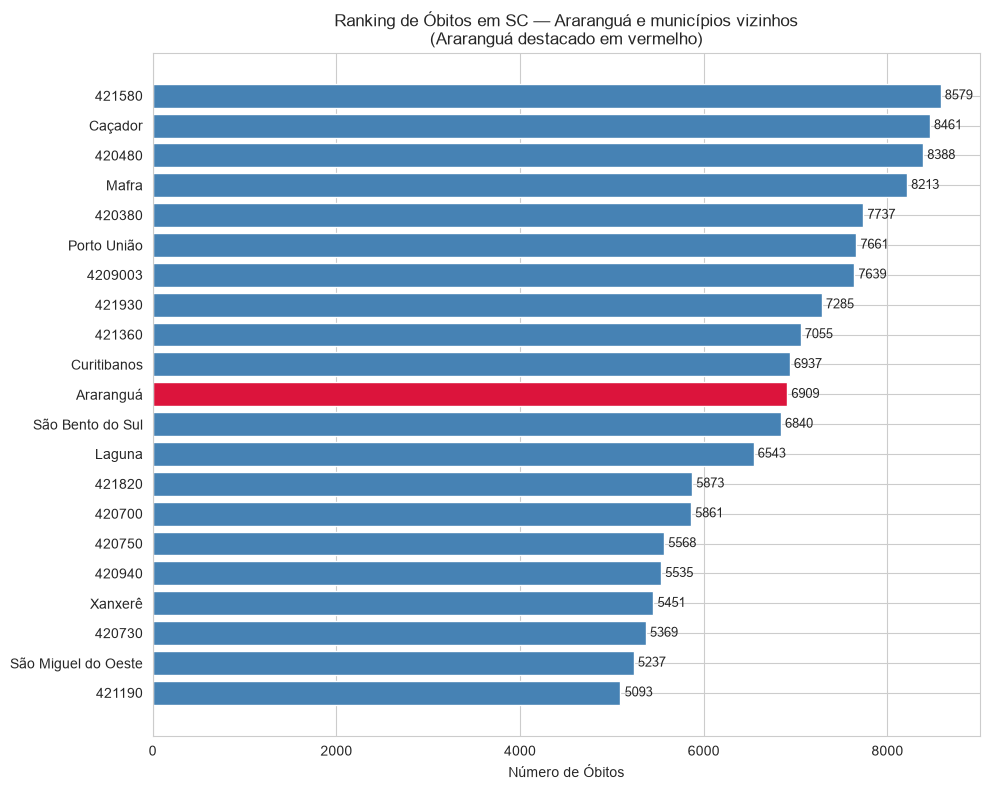

In [ ]:
contagem_municipios_sc = df[df["SC_OCORRENCIA"] == True]["CODMUNOCOR"].value_counts().reset_index()
contagem_municipios_sc.columns = ["CODMUNOCOR", "obitos"]
contagem_municipios_sc = contagem_municipios_sc.reset_index(drop=False)
contagem_municipios_sc.columns = ["posicao", "CODMUNOCOR", "obitos"]

# Posição de Araranguá no ranking
pos_ararangua = contagem_municipios_sc[contagem_municipios_sc["CODMUNOCOR"] == CODIGO_ARARANGUA]
print(f"Araranguá está na posição {pos_ararangua['posicao'].values[0] + 1} de SC")
print(f"Com {pos_ararangua['obitos'].values[0]} óbitos registrados")

# Pega os 10 acima e 10 abaixo de Araranguá no ranking
idx = pos_ararangua.index[0]
vizinhos = contagem_municipios_sc.iloc[max(0, idx-10):idx+11].copy()

vizinhos["NOME"] = vizinhos["CODMUNOCOR"].map(mapa_municipios_abrev).fillna(vizinhos["CODMUNOCOR"].astype(str))
cores = ["crimson" if cod == CODIGO_ARARANGUA else "steelblue" for cod in vizinhos["CODMUNOCOR"]]

fig, ax = plt.subplots(figsize=(10,8))
bars = ax.barh(vizinhos["NOME"], vizinhos["obitos"], color=cores)
plt.title("Ranking de Óbitos em SC — Araranguá e municípios vizinhos\n(Araranguá destacado em vermelho)")
plt.xlabel("Número de Óbitos")
ax.invert_yaxis()

# Adiciona valor em cada barra
for bar in bars:
    ax.annotate(f"{int(bar.get_width())}",
                xy=(bar.get_width(), bar.get_y() + bar.get_height() / 2),
                xytext=(3, 0), textcoords="offset points",
                va="center", fontsize=9)

plt.tight_layout()
plt.show()

In [18]:
posicao = pos_ararangua['posicao'].values[0] + 1
total_municipios = len(contagem_municipios_sc)
obitos = pos_ararangua['obitos'].values[0]

print(f"Araranguá ocupa a {posicao}ª posição no ranking de óbitos de SC")
print(f"Total de municípios no dataset: {total_municipios}")
print(f"Número de óbitos registrados: {obitos}")
print(f"Araranguá está entre os {round(posicao/total_municipios*100, 1)}% municípios com mais óbitos em SC")

Araranguá ocupa a 46ª posição no ranking de óbitos de SC
Total de municípios no dataset: 590
Número de óbitos registrados: 6909
Araranguá está entre os 7.8% municípios com mais óbitos em SC


**Interpretação:** O ranking compara Araranguá com municípios de porte similar em Santa Catarina. A posição no ranking reflete tanto o volume populacional quanto a incidência de mortes violentas. Municípios acima de Araranguá no ranking possuem mais registros de óbitos, e municípios abaixo, menos.

## 5. Distribuição de Diagnósticos por Ambiente

In [ ]:
mapa_cid = {
    "V031": "Pedestre em colisão c/ carro",
    "V041": "Pedestre em colisão c/ veículo pesado",
    "V099": "Pedestre em acidente trânsito",
    "V134": "Ciclista em colisão c/ carro",
    "V199": "Motociclista em acidente n/esp.",
    "V234": "Motociclista em colisão c/ triciclo",
    "V244": "Motociclista em colisão c/ carro",
    "V299": "Motociclista em acidente trânsito n/esp.",
    "V445": "Ocup. carro em colisão",
    "V446": "Ocup. carro em colisão (var.)",
    "V475": "Ocup. carro em colisão c/ objeto fixo",
    "V476": "Ocup. carro em colisão c/ objeto fixo",
    "V499": "Ocup. carro em acidente n/esp.",
    "V892": "Acidente trânsito (veículo n/esp.)",
    "W190": "Queda não especificada",
    "W698": "Afogamento",
    "W748": "Sufocação",
    "W749": "Sufocação não especificada",
    "X600": "Envenenamento autoinfligido",
    "X640": "Autointoxicação p/ drogas",
    "X700": "Enforcamento autoinfligido",
    "X701": "Enforcamento autoinfligido",
    "X708": "Enforcamento autoinfligido (outro)",
    "X718": "Afogamento autoinfligido",
    "X740": "Arma de fogo autoinfligida",
    "X809": "Precipitação de local elevado",
    "X934": "Agressão p/ arma de fogo (mão)",
    "X935": "Agressão p/ arma de fogo",
    "X936": "Agressão p/ arma de fogo (área n/esp.)",
    "X939": "Agressão p/ arma de fogo",
    "X950": "Agressão por arma de fogo",
    "X954": "Agressão p/ arma de fogo (público)",
    "X990": "Agressão por objeto cortante",
    "X994": "Agressão por objeto cortante (público)",
    "X995": "Agressão por objeto cortante",
    "X999": "Agressão por meio n/esp.",
    "Y004": "Agressão por objeto contundente",
    "Y000": "Agressão por objeto contundente",
    "Y09":  "Agressão por meio n/esp.",
    "Y349": "Eventos de intenção não determinada",
    "Y350": "Intervenção legal por arma de fogo",
    "X599": "Exposição a fator acidental n/esp.",
    "R99":  "Causa desconhecida",
    "R960": "Morte súbita",
}

def traduzir_cid(codigo):
    return mapa_cid.get(str(codigo), str(codigo))

In [20]:
top_causas_por_local = (
    df_limpo.groupby("LOCOCOR")["CAUSABAS"]
    .apply(lambda x: x.value_counts().head(5))
)
top_causas_por_local

LOCOCOR          
Domicilio    X700    19
             W190     2
             X740     2
             V892     2
             X990     2
Hospital     V892    51
             X599    41
             V099    10
             Y349     6
             W698     4
Ignorado     V892     4
             W698     3
             X934     1
             X935     1
             V099     1
Outros       W698    21
             W748     3
             X935     1
             X718     1
             X995     1
Via publica  V892    53
             V445    13
             V099     9
             V446     9
             V244     9
Name: CAUSABAS, dtype: int64

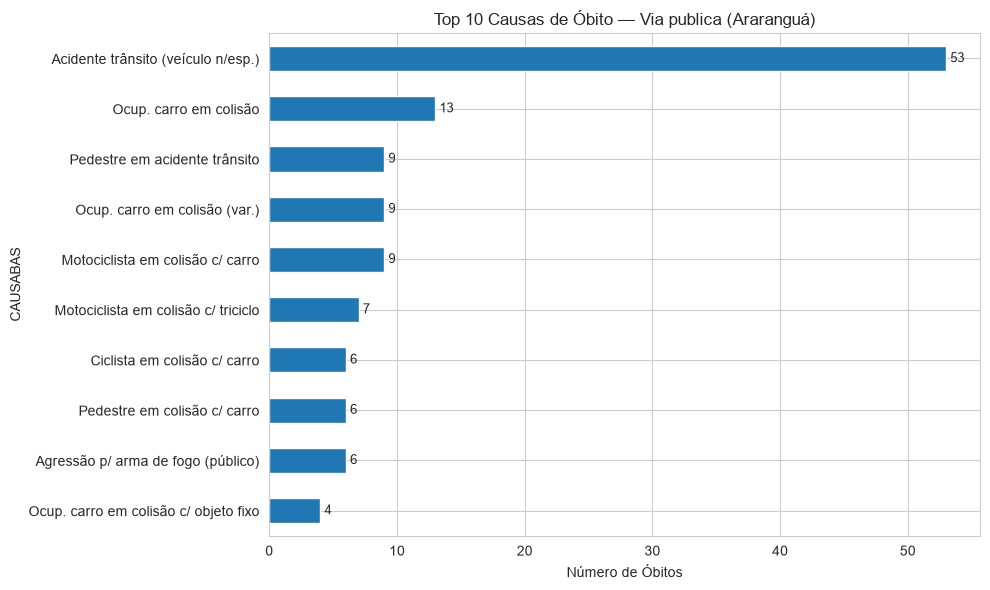

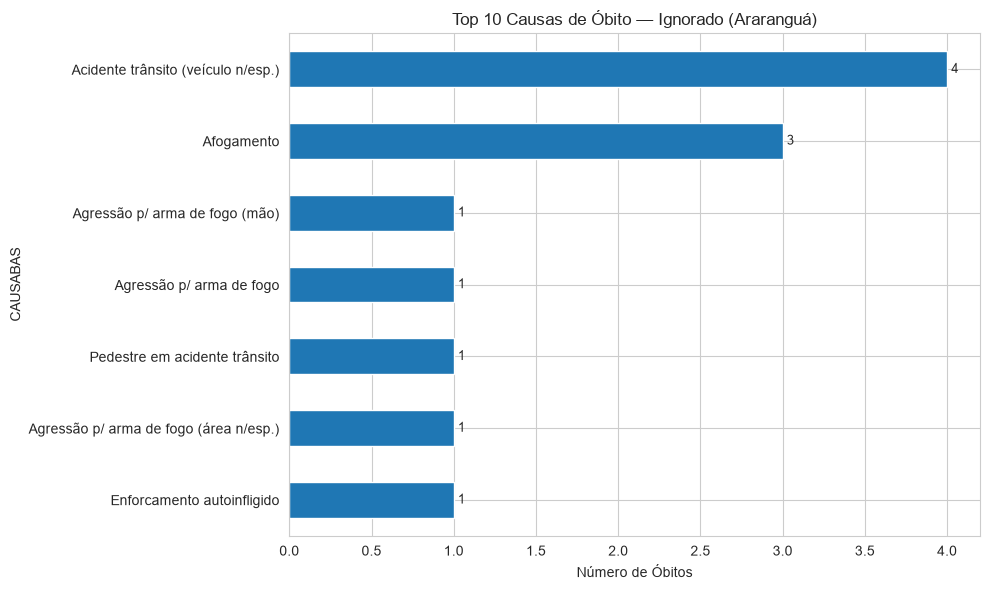

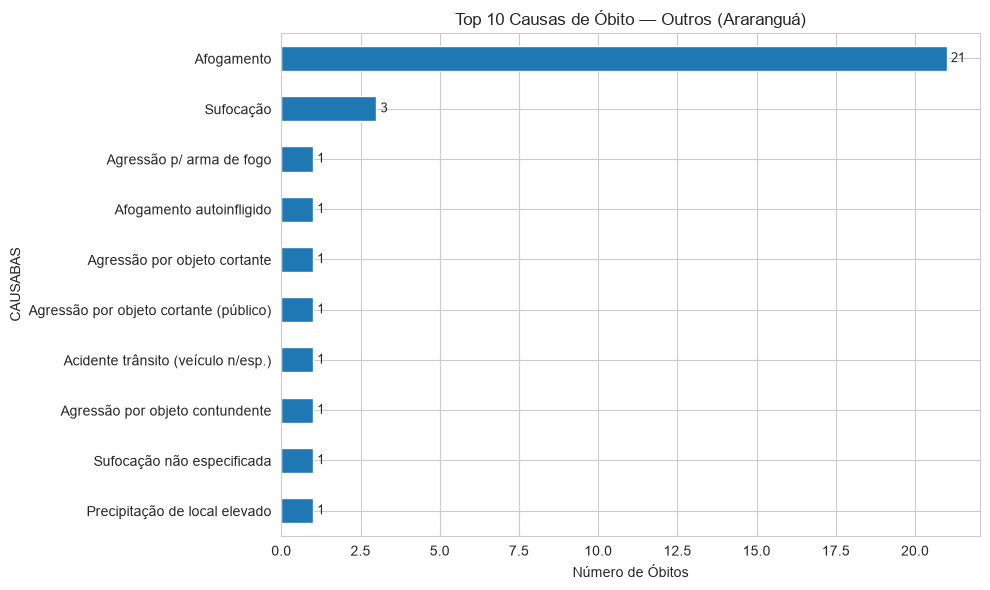

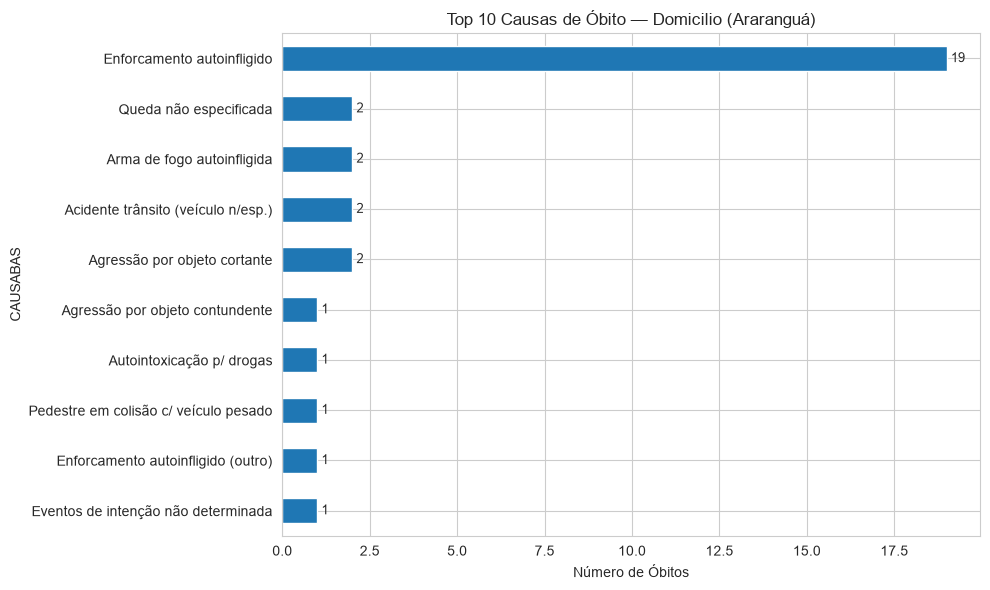

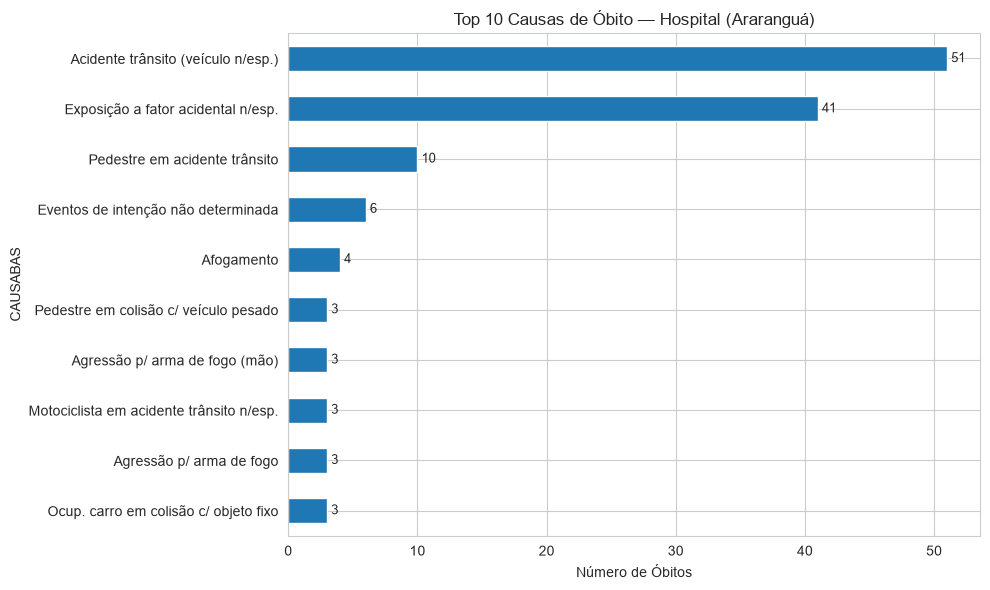

In [21]:
# Top 10 causas de óbito para cada local — um gráfico por local
locais = df_limpo["LOCOCOR"].unique()

for local in locais:
    causas_local = (
        df_limpo[df_limpo["LOCOCOR"] == local]["CAUSABAS"]
        .value_counts()
        .head(10)
    )

    if causas_local.empty:
        continue

    causas_local.index = causas_local.index.map(traduzir_cid)

    fig, ax = plt.subplots(figsize=(10, 6))
    bars = causas_local.plot(kind="barh", ax=ax)
    plt.title(f"Top 10 Causas de Óbito — {local} (Araranguá)")
    plt.xlabel("Número de Óbitos")
    ax.invert_yaxis()

    # Adiciona valor em cada barra
    for bar in ax.patches:
        ax.annotate(f"{int(bar.get_width())}",
                    xy=(bar.get_width(), bar.get_y() + bar.get_height() / 2),
                    xytext=(3, 0), textcoords="offset points",
                    va="center", fontsize=9)

    plt.tight_layout()
    plt.show()

**Interpretação:** Cada gráfico revela o perfil de causas de morte para um local específico. Via pública concentra acidentes de trânsito e agressões; hospital mostra causas externas violentas variadas de quem chegou com vida; domicílio revela eventos sem acionamento de emergência (principalmente enforcamento).

## 6. Análise por Tipo de Morte Violenta — Acidentes e Homicídios

In [22]:
# Classifica cada morte violenta por categoria
def classificar_causa(cid):
    cid = str(cid)
    if cid.startswith("V") or (cid.startswith("W")) or (cid.startswith("X") and cid[1:3].isdigit() and int(cid[1:3]) <= 59):
        return "Acidente"
    elif cid.startswith("X") and cid[1:3].isdigit() and 60 <= int(cid[1:3]) <= 84:
        return "Suicídio"
    elif (cid.startswith("X") and cid[1:3].isdigit() and int(cid[1:3]) >= 85) or cid.startswith("Y0"):
        return "Homicídio"
    else:
        return "Outros/Indeterminado"

df_limpo["TIPO_VIOLENCIA"] = df_limpo["CAUSABAS"].astype(str).apply(classificar_causa)
print(df_limpo["TIPO_VIOLENCIA"].value_counts())

TIPO_VIOLENCIA
Acidente                347
Homicídio                49
Suicídio                 41
Outros/Indeterminado     13
Name: count, dtype: int64


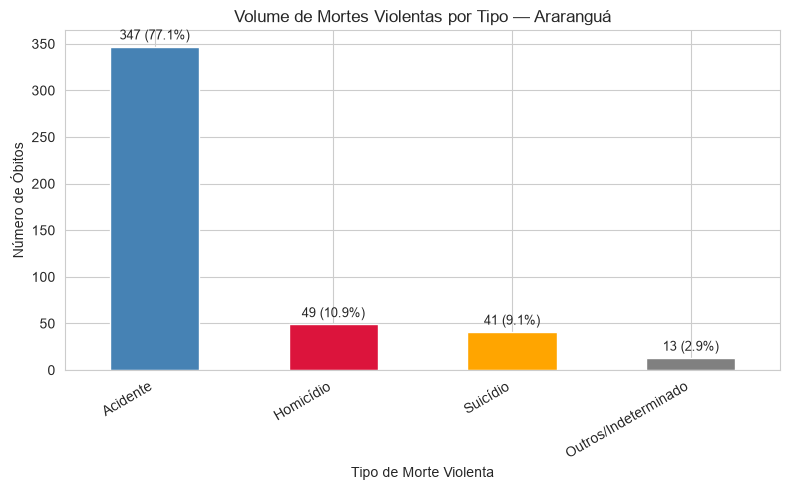

In [23]:
contagem_tipo = df_limpo["TIPO_VIOLENCIA"].value_counts()
total_tipo = contagem_tipo.sum()

fig, ax = plt.subplots(figsize=(8,5))
bars = contagem_tipo.plot(kind="bar", ax=ax, color=["steelblue","crimson","orange","gray"])
plt.title("Volume de Mortes Violentas por Tipo — Araranguá")
plt.xlabel("Tipo de Morte Violenta")
plt.ylabel("Número de Óbitos")
plt.xticks(rotation=30, ha="right")

for bar in ax.patches:
    pct = bar.get_height() / total_tipo * 100
    ax.annotate(f"{int(bar.get_height())} ({pct:.1f}%)",
                xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
                xytext=(0, 3), textcoords="offset points",
                ha="center", va="bottom", fontsize=9)

plt.tight_layout()
plt.show()

**Interpretação:** A separação por tipo permite identificar qual categoria de morte violenta é mais prevalente em Araranguá — acidentes (principalmente de trânsito), homicídios (agressões), suicídios ou causas indeterminadas. Cada categoria exige políticas públicas distintas de prevenção.

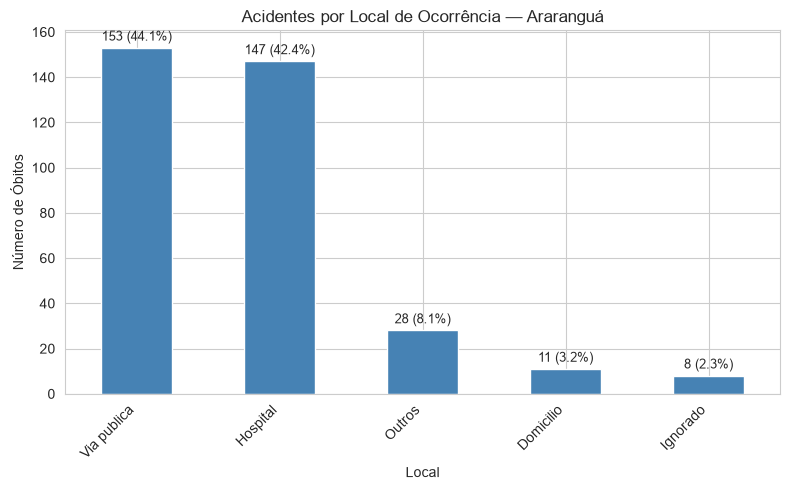

In [24]:
df_acidentes = df_limpo[df_limpo["TIPO_VIOLENCIA"] == "Acidente"]
contagem_acid_local = df_acidentes["LOCOCOR"].value_counts()
total_acid = contagem_acid_local.sum()

fig, ax = plt.subplots(figsize=(8,5))
bars = contagem_acid_local.plot(kind="bar", ax=ax, color="steelblue")
plt.title("Acidentes por Local de Ocorrência — Araranguá")
plt.xlabel("Local")
plt.ylabel("Número de Óbitos")
plt.xticks(rotation=45, ha="right")

for bar in ax.patches:
    pct = bar.get_height() / total_acid * 100
    ax.annotate(f"{int(bar.get_height())} ({pct:.1f}%)",
                xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
                xytext=(0, 3), textcoords="offset points",
                ha="center", va="bottom", fontsize=9)

plt.tight_layout()
plt.show()

**Interpretação:** Mostra onde os acidentes fatais ocorrem com mais frequência. Alta concentração em via pública indica predominância de acidentes de trânsito; óbitos em hospital indicam vítimas que receberam atendimento mas não sobreviveram.

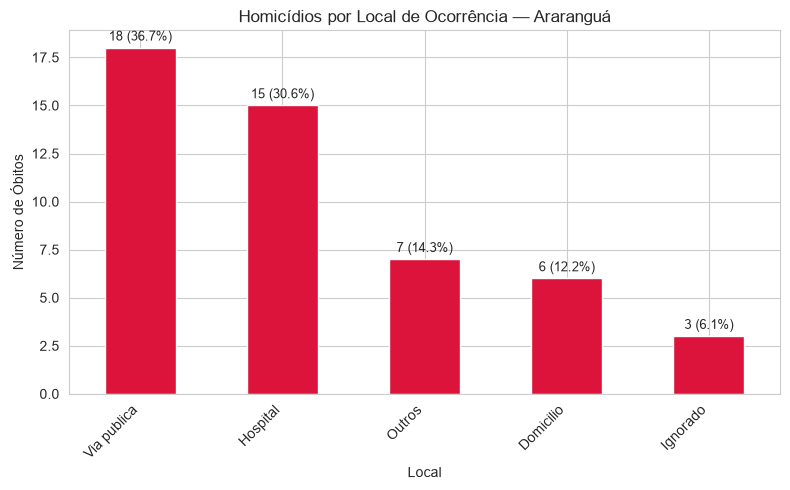

In [25]:
df_homicidios = df_limpo[df_limpo["TIPO_VIOLENCIA"] == "Homicídio"]

if len(df_homicidios) > 0:
    contagem_hom_local = df_homicidios["LOCOCOR"].value_counts()
    total_hom = contagem_hom_local.sum()

    fig, ax = plt.subplots(figsize=(8,5))
    bars = contagem_hom_local.plot(kind="bar", ax=ax, color="crimson")
    plt.title("Homicídios por Local de Ocorrência — Araranguá")
    plt.xlabel("Local")
    plt.ylabel("Número de Óbitos")
    plt.xticks(rotation=45, ha="right")

    for bar in ax.patches:
        pct = bar.get_height() / total_hom * 100
        ax.annotate(f"{int(bar.get_height())} ({pct:.1f}%)",
                    xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
                    xytext=(0, 3), textcoords="offset points",
                    ha="center", va="bottom", fontsize=9)

    plt.tight_layout()
    plt.show()
else:
    print("Nenhum homicídio encontrado no recorte atual.")

**Interpretação:** Revela onde os homicídios acontecem em Araranguá. Via pública e outros locais abertos tendem a concentrar mais casos de agressão fatal. A comparação com o gráfico de acidentes permite identificar se os dois fenômenos têm perfis geográficos distintos.

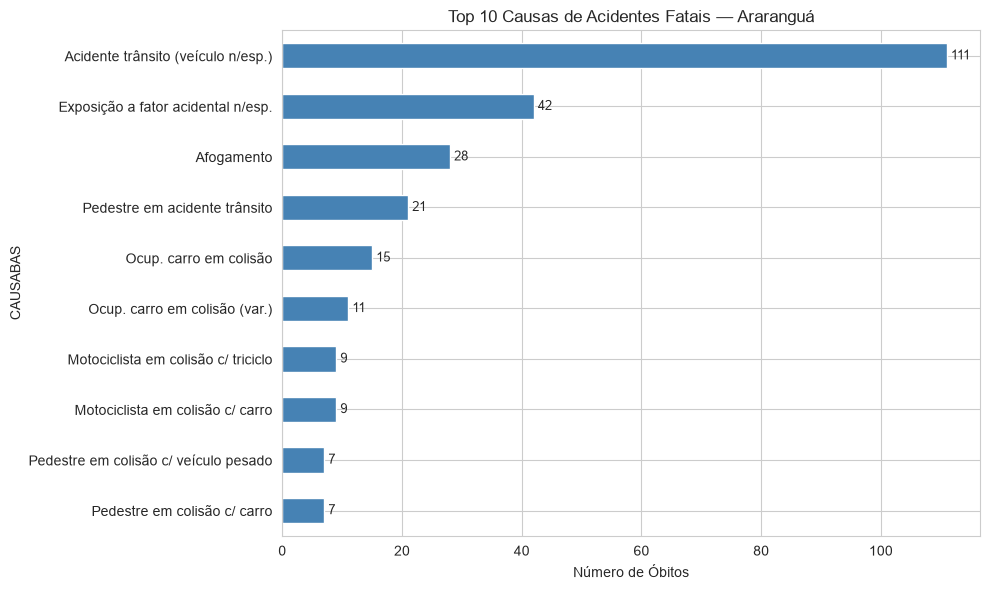

In [26]:
if len(df_acidentes) > 0:
    causas_acid = df_acidentes["CAUSABAS"].value_counts().head(10)
    causas_acid.index = causas_acid.index.map(traduzir_cid)
    total_acid_causas = causas_acid.sum()

    fig, ax = plt.subplots(figsize=(10,6))
    bars = causas_acid.plot(kind="barh", ax=ax, color="steelblue")
    plt.title("Top 10 Causas de Acidentes Fatais — Araranguá")
    plt.xlabel("Número de Óbitos")
    ax.invert_yaxis()

    for bar in ax.patches:
        ax.annotate(f"{int(bar.get_width())}",
                    xy=(bar.get_width(), bar.get_y() + bar.get_height() / 2),
                    xytext=(3, 0), textcoords="offset points",
                    va="center", fontsize=9)

    plt.tight_layout()
    plt.show()

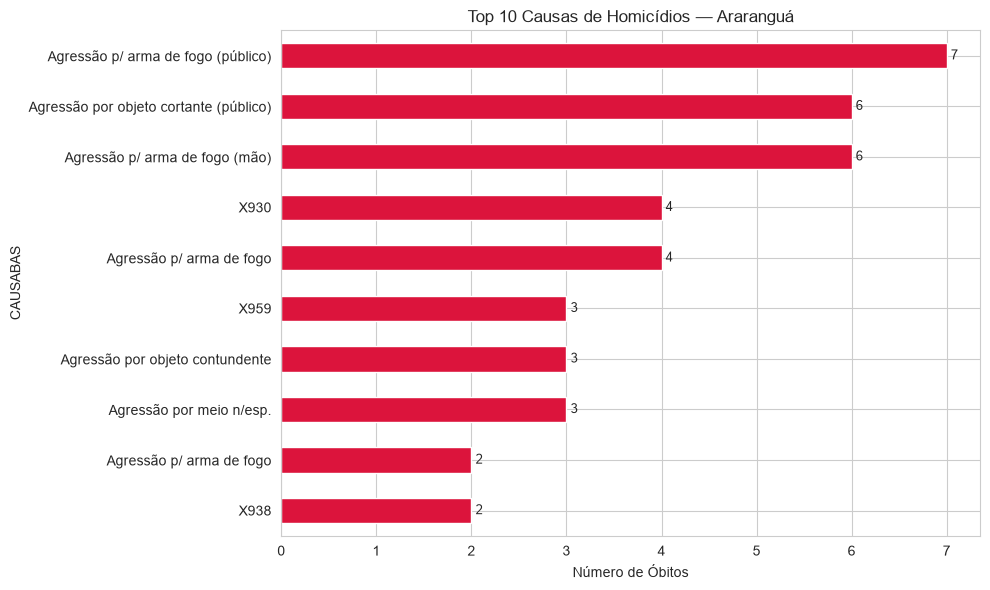

In [27]:
if len(df_homicidios) > 0:
    causas_hom = df_homicidios["CAUSABAS"].value_counts().head(10)
    causas_hom.index = causas_hom.index.map(traduzir_cid)

    fig, ax = plt.subplots(figsize=(10,6))
    bars = causas_hom.plot(kind="barh", ax=ax, color="crimson")
    plt.title("Top 10 Causas de Homicídios — Araranguá")
    plt.xlabel("Número de Óbitos")
    ax.invert_yaxis()

    for bar in ax.patches:
        ax.annotate(f"{int(bar.get_width())}",
                    xy=(bar.get_width(), bar.get_y() + bar.get_height() / 2),
                    xytext=(3, 0), textcoords="offset points",
                    va="center", fontsize=9)

    plt.tight_layout()
    plt.show()
else:
    print("Nenhum homicídio encontrado no recorte atual.")

**Interpretação:** Separar as causas por tipo de violência permite comparar diretamente o perfil dos acidentes (ex: colisões, atropelamentos) com o dos homicídios (ex: arma de fogo, objeto cortante). Essa distinção é fundamental para direcionar políticas públicas — trânsito versus segurança pública.